# Sample Efficiency of Soft Actor-Critic on `Pendulum-v1`

This notebook investigates how the deterministic performance of a custom TensorFlow/Keras Soft Actor-Critic (SAC) agent changes as the amount of environment interaction increases.

SAC is an off-policy actor-critic method for continuous control. It combines expected-return maximisation with an entropy term, uses replay memory, and learns twin critic networks together with a stochastic actor [1], [2]. This makes it a suitable extension beyond the discrete-action Deep Q-Network studied in class [3].

## Experimental question

**At what interaction budget does this SAC configuration begin to show diminishing performance improvements on `Pendulum-v1`?**

The reported budgets are 5,000, 15,000, 30,000 and 60,000 interactions. Three independently seeded agents are used. Each reported checkpoint is evaluated deterministically with the same five reset seeds.

The network is deliberately small because the recorded experiment ran on CPU. The implementation still contains the main SAC components: a squashed Gaussian actor, twin critics, slowly updated target critics, replay memory and automatic entropy-temperature adjustment.


# 1. Environment and package setup

The completed run used:

- Python 3.8.20
- TensorFlow 2.13.0
- Gymnasium 0.29.1
- NumPy 1.24.3
- Pandas 2.0.3

Run the installation cell only when packages are missing, then restart the kernel. The notebook automatically selects a TensorFlow GPU when one is available and otherwise uses the CPU.


In [1]:
# Run only when these packages are missing, then restart the kernel.
# %pip install tensorflow==2.13.0 gymnasium[classic_control]==0.29.1 pandas==2.0.3 matplotlib scipy


In [2]:
# Imports and package checks

import gc
import os
import random
import sys
import time
from dataclasses import dataclass
from pathlib import Path

import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")

print("Python:", sys.version.split()[0])
print("TensorFlow:", tf.__version__)
print("Gymnasium:", gym.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)


Python: 3.8.20
TensorFlow: 2.13.0
Gymnasium: 0.29.1
NumPy: 1.24.3
Pandas: 2.0.3


In [3]:
# TensorFlow device detection

physical_gpus = tf.config.list_physical_devices("GPU")

for gpu in physical_gpus:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError as error:
        print("GPU memory-growth setting was not changed:", error)

COMPUTE_DEVICE = "/GPU:0" if physical_gpus else "/CPU:0"

print("Detected TensorFlow GPUs:", physical_gpus)
print("TensorFlow built with CUDA:", tf.test.is_built_with_cuda())
print("Selected compute device:", COMPUTE_DEVICE)


Detected TensorFlow GPUs: []
TensorFlow built with CUDA: False
Selected compute device: /CPU:0


# 2. Experiment settings

The architecture and learning settings are held constant for every seed and budget. The main experimental variable is therefore the amount of environment interaction.

`RUN_TRAINING` is set to `False` by default so that **Run All** does not accidentally start a lengthy retraining session. Change it to `True` only when intentionally reproducing the experiment.


In [4]:
# Experiment controls

RUN_TRAINING = False
SKIP_COMPLETED_SEEDS = True

OUTPUT_ROOT = Path("sac_pendulum_outputs_final")
MODEL_DIR = OUTPUT_ROOT / "models"
RESULTS_DIR = OUTPUT_ROOT / "results"
FIGURE_DIR = OUTPUT_ROOT / "figures"

for directory in [OUTPUT_ROOT, MODEL_DIR, RESULTS_DIR, FIGURE_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

TRAINING_SEEDS = [42, 43, 44]
CHECKPOINT_BUDGETS = [5_000, 15_000, 30_000, 60_000]
TOTAL_TRAINING_STEPS = 60_000
PERIODIC_EVALUATION_INTERVAL = 5_000

# The same fixed initial conditions are used for comparisons.
EVALUATION_SEEDS = [2_000, 2_001, 2_002, 2_003, 2_004]
PERIODIC_EVALUATION_SEEDS = EVALUATION_SEEDS.copy()

print("Training seeds:", TRAINING_SEEDS)
print("Reported budgets:", CHECKPOINT_BUDGETS)
print("Evaluation episodes per budget:", len(EVALUATION_SEEDS))
print("Run training:", RUN_TRAINING)


Training seeds: [42, 43, 44]
Reported budgets: [5000, 15000, 30000, 60000]
Evaluation episodes per budget: 5
Run training: False


In [5]:
@dataclass(frozen=True)
class SACConfig:
    environment_id: str = "Pendulum-v1"

    actor_hidden_units: tuple = (64, 64)
    critic_hidden_units: tuple = (64, 64)

    actor_learning_rate: float = 0.001
    critic_learning_rate: float = 0.001
    alpha_learning_rate: float = 0.001

    gamma: float = 0.99
    tau: float = 0.005

    replay_capacity: int = 100_000
    batch_size: int = 64
    learning_starts: int = 1_000

    # One update every two interactions reduces CPU runtime.
    training_frequency: int = 2
    updates_per_training_step: int = 1

    initial_log_alpha: float = 0.0
    log_std_minimum: float = -20.0
    log_std_maximum: float = 2.0
    gradient_clip_norm: float = 10.0

    bootstrap_resamples: int = 10_000
    diminishing_returns_tolerance: float = 20.0


# This line must remain outside the class definition.
CONFIG = SACConfig()
CONFIG


SACConfig(environment_id='Pendulum-v1', actor_hidden_units=(64, 64), critic_hidden_units=(64, 64), actor_learning_rate=0.001, critic_learning_rate=0.001, alpha_learning_rate=0.001, gamma=0.99, tau=0.005, replay_capacity=100000, batch_size=64, learning_starts=1000, training_frequency=2, updates_per_training_step=1, initial_log_alpha=0.0, log_std_minimum=-20.0, log_std_maximum=2.0, gradient_clip_norm=10.0, bootstrap_resamples=10000, diminishing_returns_tolerance=20.0)

# 3. Reproducibility and environment helpers

In [6]:
def set_global_seed(seed):
    """Set the main pseudo-random number generators."""

    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)


def make_environment(seed=None, render_mode=None):
    """Create a Gymnasium Pendulum-v1 environment."""

    environment = gym.make(
        CONFIG.environment_id,
        render_mode=render_mode,
    )

    if seed is not None:
        environment.reset(seed=int(seed))
        environment.action_space.seed(int(seed))

    return environment


def bootstrap_mean_confidence_interval(
    values,
    confidence=0.95,
    resamples=10_000,
    seed=2026,
):
    """Calculate a percentile bootstrap confidence interval for a mean."""

    values = np.asarray(values, dtype=np.float64)

    if values.ndim != 1 or len(values) == 0:
        raise ValueError("values must be a non-empty one-dimensional sequence.")

    rng = np.random.default_rng(seed)

    sampled_indices = rng.integers(
        0,
        len(values),
        size=(int(resamples), len(values)),
    )

    bootstrap_means = values[sampled_indices].mean(axis=1)

    alpha = 1.0 - confidence
    lower = float(np.quantile(bootstrap_means, alpha / 2.0))
    upper = float(np.quantile(bootstrap_means, 1.0 - alpha / 2.0))

    return lower, upper


set_global_seed(42)

test_environment = make_environment(seed=42)
test_observation, test_info = test_environment.reset(seed=42)

print("Observation shape:", test_observation.shape)
print("Action space:", test_environment.action_space)
print("Maximum episode steps:", test_environment.spec.max_episode_steps)
print("Initial observation:", test_observation)

test_environment.close()


Observation shape: (3,)
Action space: Box(-2.0, 2.0, (1,), float32)
Maximum episode steps: 200
Initial observation: [-0.14995256  0.9886932  -0.12224312]


# 4. Replay buffer

In [7]:
class ReplayBuffer:
    """Fixed-size NumPy replay buffer for off-policy training."""

    def __init__(
        self,
        observation_dimension,
        action_dimension,
        capacity,
        seed,
    ):
        if capacity <= 0:
            raise ValueError("Replay capacity must be positive.")

        self.capacity = int(capacity)
        self.rng = np.random.default_rng(seed)

        self.observations = np.zeros(
            (self.capacity, observation_dimension),
            dtype=np.float32,
        )

        self.actions = np.zeros(
            (self.capacity, action_dimension),
            dtype=np.float32,
        )

        self.rewards = np.zeros(
            (self.capacity, 1),
            dtype=np.float32,
        )

        self.next_observations = np.zeros(
            (self.capacity, observation_dimension),
            dtype=np.float32,
        )

        self.terminals = np.zeros(
            (self.capacity, 1),
            dtype=np.float32,
        )

        self.position = 0
        self.size = 0

    def add(
        self,
        observation,
        action,
        reward,
        next_observation,
        terminal,
    ):
        index = self.position

        self.observations[index] = np.asarray(
            observation,
            dtype=np.float32,
        )

        self.actions[index] = np.asarray(
            action,
            dtype=np.float32,
        )

        self.rewards[index] = float(reward)

        self.next_observations[index] = np.asarray(
            next_observation,
            dtype=np.float32,
        )

        self.terminals[index] = float(terminal)

        self.position = (self.position + 1) % self.capacity
        self.size = min(self.size + 1, self.capacity)

    def sample(self, batch_size):
        if self.size < batch_size:
            raise ValueError(
                f"Replay buffer contains {self.size} transitions, "
                f"but batch size is {batch_size}."
            )

        indices = self.rng.integers(
            0,
            self.size,
            size=int(batch_size),
        )

        return {
            "observations": self.observations[indices],
            "actions": self.actions[indices],
            "rewards": self.rewards[indices],
            "next_observations": self.next_observations[indices],
            "terminals": self.terminals[indices],
        }

    def __len__(self):
        return self.size


# 5. Actor and critic networks

The actor predicts the mean and log standard deviation of a Gaussian policy. Its sampled value is passed through `tanh` and rescaled to the environment's torque limits. Two critics independently estimate action value, and the smaller estimate is used in the SAC target to reduce optimistic value estimation [1], [2].


In [8]:
LOG_TWO_PI = float(np.log(2.0 * np.pi))


class GaussianActor(tf.keras.Model):
    """Squashed Gaussian actor that outputs continuous Pendulum torque."""

    def __init__(
        self,
        observation_dimension,
        action_low,
        action_high,
        hidden_units,
        log_std_minimum,
        log_std_maximum,
    ):
        super().__init__(name="gaussian_actor")

        self.observation_dimension = int(observation_dimension)
        self.hidden_units = tuple(hidden_units)

        self.action_low = tf.constant(
            np.asarray(action_low, dtype=np.float32),
            dtype=tf.float32,
        )

        self.action_high = tf.constant(
            np.asarray(action_high, dtype=np.float32),
            dtype=tf.float32,
        )

        self.action_scale = (self.action_high - self.action_low) / 2.0
        self.action_bias = (self.action_high + self.action_low) / 2.0

        self.log_std_minimum = float(log_std_minimum)
        self.log_std_maximum = float(log_std_maximum)

        self.hidden_layers_list = [
            tf.keras.layers.Dense(
                units,
                activation="relu",
                kernel_initializer="he_uniform",
                name=f"actor_hidden_{index}",
            )
            for index, units in enumerate(hidden_units, start=1)
        ]

        action_dimension = int(np.prod(np.asarray(action_low).shape))

        self.mean_layer = tf.keras.layers.Dense(
            action_dimension,
            activation=None,
            name="actor_mean",
        )

        self.log_std_layer = tf.keras.layers.Dense(
            action_dimension,
            activation=None,
            name="actor_log_std",
        )

    def call(self, observations, training=False):
        x = tf.convert_to_tensor(observations, dtype=tf.float32)

        for layer in self.hidden_layers_list:
            x = layer(x, training=training)

        mean = self.mean_layer(x, training=training)

        log_std = self.log_std_layer(x, training=training)
        log_std = tf.clip_by_value(
            log_std,
            self.log_std_minimum,
            self.log_std_maximum,
        )

        return mean, log_std

    def sample(self, observations, deterministic=False, training=False):
        mean, log_std = self(
            observations,
            training=training,
        )

        if deterministic:
            pre_tanh = mean
        else:
            standard_deviation = tf.exp(log_std)
            noise = tf.random.normal(tf.shape(mean), dtype=tf.float32)
            pre_tanh = mean + standard_deviation * noise

        squashed_action = tf.tanh(pre_tanh)
        scaled_action = self.action_bias + self.action_scale * squashed_action

        if deterministic:
            log_probability = tf.zeros(
                (tf.shape(mean)[0], 1),
                dtype=tf.float32,
            )
        else:
            standard_deviation = tf.exp(log_std)

            gaussian_log_probability = -0.5 * (
                tf.square((pre_tanh - mean) / (standard_deviation + 1e-8))
                + 2.0 * log_std
                + LOG_TWO_PI
            )

            gaussian_log_probability = tf.reduce_sum(
                gaussian_log_probability,
                axis=-1,
                keepdims=True,
            )

            tanh_correction = tf.reduce_sum(
                tf.math.log(1.0 - tf.square(squashed_action) + 1e-6),
                axis=-1,
                keepdims=True,
            )

            scale_correction = tf.reduce_sum(
                tf.math.log(tf.abs(self.action_scale) + 1e-6)
            )

            log_probability = (
                gaussian_log_probability
                - tanh_correction
                - scale_correction
            )

        return scaled_action, log_probability

    def get_config(self):
        return {
            "observation_dimension": self.observation_dimension,
            "action_low": self.action_low.numpy().tolist(),
            "action_high": self.action_high.numpy().tolist(),
            "hidden_units": self.hidden_units,
            "log_std_minimum": self.log_std_minimum,
            "log_std_maximum": self.log_std_maximum,
        }


class Critic(tf.keras.Model):
    """Q-network that estimates the value of an observation-action pair."""

    def __init__(self, hidden_units, name):
        super().__init__(name=name)

        self.hidden_units = tuple(hidden_units)
        self.model_name = name

        self.hidden_layers_list = [
            tf.keras.layers.Dense(
                units,
                activation="relu",
                kernel_initializer="he_uniform",
                name=f"{name}_hidden_{index}",
            )
            for index, units in enumerate(hidden_units, start=1)
        ]

        self.output_layer = tf.keras.layers.Dense(
            1,
            activation=None,
            name=f"{name}_q_value",
        )

    def call(self, observations, actions, training=False):
        observations = tf.convert_to_tensor(
            observations,
            dtype=tf.float32,
        )

        actions = tf.convert_to_tensor(
            actions,
            dtype=tf.float32,
        )

        x = tf.concat(
            [observations, actions],
            axis=-1,
        )

        for layer in self.hidden_layers_list:
            x = layer(x, training=training)

        return self.output_layer(x, training=training)

    def get_config(self):
        return {
            "hidden_units": self.hidden_units,
            "name": self.model_name,
        }


# 6. SAC agent

The agent contains:

- one stochastic Gaussian actor;
- two trainable critics;
- two target critics;
- automatic entropy-temperature adjustment;
- replay-buffer updates;
- soft target-network updates;
- gradient clipping.


In [9]:
class SACAgent:
    """TensorFlow/Keras implementation of Soft Actor-Critic."""

    def __init__(
        self,
        observation_dimension,
        action_low,
        action_high,
        config,
    ):
        self.observation_dimension = int(observation_dimension)

        self.action_low = np.asarray(
            action_low,
            dtype=np.float32,
        )

        self.action_high = np.asarray(
            action_high,
            dtype=np.float32,
        )

        self.action_dimension = int(
            np.prod(self.action_low.shape)
        )

        self.config = config
        self.target_entropy = -float(self.action_dimension)

        with tf.device(COMPUTE_DEVICE):
            self.actor = GaussianActor(
                observation_dimension=self.observation_dimension,
                action_low=self.action_low,
                action_high=self.action_high,
                hidden_units=config.actor_hidden_units,
                log_std_minimum=config.log_std_minimum,
                log_std_maximum=config.log_std_maximum,
            )

            self.critic_1 = Critic(
                hidden_units=config.critic_hidden_units,
                name="critic_1",
            )

            self.critic_2 = Critic(
                hidden_units=config.critic_hidden_units,
                name="critic_2",
            )

            self.target_critic_1 = Critic(
                hidden_units=config.critic_hidden_units,
                name="target_critic_1",
            )

            self.target_critic_2 = Critic(
                hidden_units=config.critic_hidden_units,
                name="target_critic_2",
            )

            self.actor_optimizer = tf.keras.optimizers.Adam(
                learning_rate=config.actor_learning_rate,
            )

            self.critic_1_optimizer = tf.keras.optimizers.Adam(
                learning_rate=config.critic_learning_rate,
            )

            self.critic_2_optimizer = tf.keras.optimizers.Adam(
                learning_rate=config.critic_learning_rate,
            )

            self.alpha_optimizer = tf.keras.optimizers.Adam(
                learning_rate=config.alpha_learning_rate,
            )

            self.log_alpha = tf.Variable(
                config.initial_log_alpha,
                trainable=True,
                dtype=tf.float32,
                name="log_alpha",
            )

            self._build_networks()
            self.hard_update_target_critics()

            self.checkpoint = tf.train.Checkpoint(
                actor=self.actor,
                critic_1=self.critic_1,
                critic_2=self.critic_2,
                target_critic_1=self.target_critic_1,
                target_critic_2=self.target_critic_2,
                actor_optimizer=self.actor_optimizer,
                critic_1_optimizer=self.critic_1_optimizer,
                critic_2_optimizer=self.critic_2_optimizer,
                alpha_optimizer=self.alpha_optimizer,
                log_alpha=self.log_alpha,
            )

    def _build_networks(self):
        dummy_observation = tf.zeros(
            (1, self.observation_dimension),
            dtype=tf.float32,
        )

        dummy_action = tf.zeros(
            (1, self.action_dimension),
            dtype=tf.float32,
        )

        self.actor(dummy_observation)
        self.critic_1(dummy_observation, dummy_action)
        self.critic_2(dummy_observation, dummy_action)
        self.target_critic_1(dummy_observation, dummy_action)
        self.target_critic_2(dummy_observation, dummy_action)

    @property
    def alpha(self):
        return tf.exp(self.log_alpha)

    def hard_update_target_critics(self):
        self.target_critic_1.set_weights(
            self.critic_1.get_weights()
        )

        self.target_critic_2.set_weights(
            self.critic_2.get_weights()
        )

    def soft_update_target_critics(self):
        tau = self.config.tau

        for target_variable, source_variable in zip(
            self.target_critic_1.variables,
            self.critic_1.variables,
        ):
            target_variable.assign(
                tau * source_variable
                + (1.0 - tau) * target_variable
            )

        for target_variable, source_variable in zip(
            self.target_critic_2.variables,
            self.critic_2.variables,
        ):
            target_variable.assign(
                tau * source_variable
                + (1.0 - tau) * target_variable
            )

    def select_action(self, observation, deterministic=False):
        observation_batch = np.asarray(
            observation,
            dtype=np.float32,
        )[None, :]

        action, _ = self.actor.sample(
            observation_batch,
            deterministic=deterministic,
            training=False,
        )

        return action.numpy()[0]

    @tf.function(reduce_retracing=True)
    def train_on_batch(
        self,
        observations,
        actions,
        rewards,
        next_observations,
        terminals,
    ):
        observations = tf.convert_to_tensor(
            observations,
            dtype=tf.float32,
        )

        actions = tf.convert_to_tensor(
            actions,
            dtype=tf.float32,
        )

        rewards = tf.convert_to_tensor(
            rewards,
            dtype=tf.float32,
        )

        next_observations = tf.convert_to_tensor(
            next_observations,
            dtype=tf.float32,
        )

        terminals = tf.convert_to_tensor(
            terminals,
            dtype=tf.float32,
        )

        with tf.GradientTape() as critic_1_tape, tf.GradientTape() as critic_2_tape:
            next_actions, next_log_probabilities = self.actor.sample(
                next_observations,
                deterministic=False,
                training=True,
            )

            next_target_q_1 = self.target_critic_1(
                next_observations,
                next_actions,
                training=False,
            )

            next_target_q_2 = self.target_critic_2(
                next_observations,
                next_actions,
                training=False,
            )

            next_target_q = tf.minimum(
                next_target_q_1,
                next_target_q_2,
            )

            entropy_adjusted_next_q = (
                next_target_q
                - tf.stop_gradient(self.alpha)
                * next_log_probabilities
            )

            target_q = rewards + (
                self.config.gamma
                * (1.0 - terminals)
                * entropy_adjusted_next_q
            )

            target_q = tf.stop_gradient(target_q)

            current_q_1 = self.critic_1(
                observations,
                actions,
                training=True,
            )

            current_q_2 = self.critic_2(
                observations,
                actions,
                training=True,
            )

            critic_1_loss = tf.reduce_mean(
                tf.square(current_q_1 - target_q)
            )

            critic_2_loss = tf.reduce_mean(
                tf.square(current_q_2 - target_q)
            )

        critic_1_gradients = critic_1_tape.gradient(
            critic_1_loss,
            self.critic_1.trainable_variables,
        )

        critic_2_gradients = critic_2_tape.gradient(
            critic_2_loss,
            self.critic_2.trainable_variables,
        )

        critic_1_gradients, _ = tf.clip_by_global_norm(
            critic_1_gradients,
            self.config.gradient_clip_norm,
        )

        critic_2_gradients, _ = tf.clip_by_global_norm(
            critic_2_gradients,
            self.config.gradient_clip_norm,
        )

        self.critic_1_optimizer.apply_gradients(
            zip(
                critic_1_gradients,
                self.critic_1.trainable_variables,
            )
        )

        self.critic_2_optimizer.apply_gradients(
            zip(
                critic_2_gradients,
                self.critic_2.trainable_variables,
            )
        )

        with tf.GradientTape() as actor_tape:
            new_actions, log_probabilities = self.actor.sample(
                observations,
                deterministic=False,
                training=True,
            )

            q_1_for_policy = self.critic_1(
                observations,
                new_actions,
                training=False,
            )

            q_2_for_policy = self.critic_2(
                observations,
                new_actions,
                training=False,
            )

            minimum_q_for_policy = tf.minimum(
                q_1_for_policy,
                q_2_for_policy,
            )

            actor_loss = tf.reduce_mean(
                tf.stop_gradient(self.alpha)
                * log_probabilities
                - minimum_q_for_policy
            )

        actor_gradients = actor_tape.gradient(
            actor_loss,
            self.actor.trainable_variables,
        )

        actor_gradients, _ = tf.clip_by_global_norm(
            actor_gradients,
            self.config.gradient_clip_norm,
        )

        self.actor_optimizer.apply_gradients(
            zip(
                actor_gradients,
                self.actor.trainable_variables,
            )
        )

        with tf.GradientTape() as alpha_tape:
            _, log_probabilities_for_alpha = self.actor.sample(
                observations,
                deterministic=False,
                training=False,
            )

            alpha_loss = -tf.reduce_mean(
                self.log_alpha
                * tf.stop_gradient(
                    log_probabilities_for_alpha
                    + self.target_entropy
                )
            )

        alpha_gradient = alpha_tape.gradient(
            alpha_loss,
            [self.log_alpha],
        )

        self.alpha_optimizer.apply_gradients(
            zip(alpha_gradient, [self.log_alpha])
        )

        self.soft_update_target_critics()

        return {
            "critic_1_loss": critic_1_loss,
            "critic_2_loss": critic_2_loss,
            "actor_loss": actor_loss,
            "alpha_loss": alpha_loss,
            "alpha": self.alpha,
        }

    def update_from_replay(self, replay_buffer):
        batch = replay_buffer.sample(
            self.config.batch_size
        )

        training_metrics = self.train_on_batch(
            observations=batch["observations"],
            actions=batch["actions"],
            rewards=batch["rewards"],
            next_observations=batch["next_observations"],
            terminals=batch["terminals"],
        )

        return {
            key: float(value.numpy())
            for key, value in training_metrics.items()
        }

    def save_checkpoint(self, directory, step):
        directory = Path(directory)
        directory.mkdir(parents=True, exist_ok=True)

        manager = tf.train.CheckpointManager(
            checkpoint=self.checkpoint,
            directory=str(directory),
            max_to_keep=10,
        )

        checkpoint_path = manager.save(
            checkpoint_number=int(step)
        )

        return checkpoint_path

    def restore_latest_checkpoint(self, directory):
        directory = Path(directory)

        latest_checkpoint = tf.train.latest_checkpoint(
            str(directory)
        )

        if latest_checkpoint is None:
            raise FileNotFoundError(
                f"No TensorFlow checkpoint found in {directory.resolve()}."
            )

        status = self.checkpoint.restore(
            latest_checkpoint
        )

        status.expect_partial()

        return latest_checkpoint


# 7. Deterministic evaluation

In [10]:
def evaluate_agent(
    agent,
    evaluation_seeds,
    maximum_episode_steps=200,
):
    """Evaluate one policy deterministically using fixed initial conditions."""

    evaluation_rows = []

    evaluation_environment = make_environment(
        seed=evaluation_seeds[0]
    )

    try:
        for evaluation_seed in evaluation_seeds:
            observation, info = evaluation_environment.reset(
                seed=int(evaluation_seed)
            )

            episode_return = 0.0
            episode_length = 0

            for step in range(maximum_episode_steps):
                action = agent.select_action(
                    observation,
                    deterministic=True,
                )

                (
                    next_observation,
                    reward,
                    terminated,
                    truncated,
                    info,
                ) = evaluation_environment.step(action)

                episode_return += float(reward)
                episode_length += 1
                observation = next_observation

                if terminated or truncated:
                    break

            evaluation_rows.append({
                "evaluation_seed": int(evaluation_seed),
                "episode_return": float(episode_return),
                "episode_length": int(episode_length),
            })
    finally:
        evaluation_environment.close()

    evaluation_dataframe = pd.DataFrame(
        evaluation_rows
    )

    return evaluation_dataframe


# 8. Training and checkpoint evaluation

Each seed is trained continuously to 60,000 interactions. Evaluation is performed every 5,000 interactions, while the four paper budgets are saved as checkpoints.

Gymnasium distinguishes genuine task termination from time-limit truncation [5]. `Pendulum-v1` normally ends because of its 200-step time limit, so the replay buffer stores only the `terminated` flag as terminal. This prevents the critic target from incorrectly discarding future value at a time-limit boundary.


In [11]:
def seed_run_is_complete(seed):
    expected_file = (
        RESULTS_DIR
        / f"seed_{seed}_checkpoint_evaluations.csv"
    )

    if not expected_file.exists():
        return False

    try:
        dataframe = pd.read_csv(expected_file)
    except (pd.errors.EmptyDataError, OSError):
        return False

    if dataframe.empty or "budget" not in dataframe.columns:
        return False

    completed_budgets = set(
        dataframe["budget"].astype(int).unique()
    )

    return set(CHECKPOINT_BUDGETS).issubset(
        completed_budgets
    )


def train_single_seed(seed):
    """Train one SAC agent and evaluate all periodic/checkpoint budgets."""

    set_global_seed(seed)

    environment = make_environment(seed=seed)

    observation_dimension = int(
        environment.observation_space.shape[0]
    )

    action_low = environment.action_space.low
    action_high = environment.action_space.high

    replay_buffer = ReplayBuffer(
        observation_dimension=observation_dimension,
        action_dimension=int(environment.action_space.shape[0]),
        capacity=CONFIG.replay_capacity,
        seed=seed,
    )

    with tf.device(COMPUTE_DEVICE):
        agent = SACAgent(
            observation_dimension=observation_dimension,
            action_low=action_low,
            action_high=action_high,
            config=CONFIG,
        )

    observation, info = environment.reset(
        seed=seed
    )

    environment.action_space.seed(seed)

    periodic_evaluation_rows = []
    checkpoint_evaluation_rows = []
    training_log_rows = []
    checkpoint_time_rows = []

    episode_return = 0.0
    episode_length = 0
    episode_number = 0

    recent_training_metrics = []

    training_start_time = time.perf_counter()

    evaluation_steps = set(
        range(
            PERIODIC_EVALUATION_INTERVAL,
            TOTAL_TRAINING_STEPS + 1,
            PERIODIC_EVALUATION_INTERVAL,
        )
    )

    evaluation_steps.update(
        CHECKPOINT_BUDGETS
    )

    try:
        for environment_step in range(
            1,
            TOTAL_TRAINING_STEPS + 1,
        ):
            if environment_step <= CONFIG.learning_starts:
                action = environment.action_space.sample()
            else:
                action = agent.select_action(
                    observation,
                    deterministic=False,
                )

            (
                next_observation,
                reward,
                terminated,
                truncated,
                info,
            ) = environment.step(action)

            replay_buffer.add(
                observation=observation,
                action=action,
                reward=reward,
                next_observation=next_observation,
                terminal=terminated,
            )

            observation = next_observation
            episode_return += float(reward)
            episode_length += 1

            if (
                environment_step >= CONFIG.learning_starts
                and len(replay_buffer) >= CONFIG.batch_size
                and environment_step % CONFIG.training_frequency == 0
            ):
                for _ in range(
                    CONFIG.updates_per_training_step
                ):
                    metrics = agent.update_from_replay(
                        replay_buffer
                    )

                    recent_training_metrics.append(
                        metrics
                    )

            if terminated or truncated:
                training_log_rows.append({
                    "training_seed": int(seed),
                    "episode": int(episode_number),
                    "environment_step": int(environment_step),
                    "episode_return": float(episode_return),
                    "episode_length": int(episode_length),
                })

                episode_number += 1
                episode_return = 0.0
                episode_length = 0

                observation, info = environment.reset()

            if environment_step in evaluation_steps:
                current_evaluation_seeds = (
                    EVALUATION_SEEDS
                    if environment_step in CHECKPOINT_BUDGETS
                    else PERIODIC_EVALUATION_SEEDS
                )

                evaluation_dataframe = evaluate_agent(
                    agent=agent,
                    evaluation_seeds=current_evaluation_seeds,
                    maximum_episode_steps=environment.spec.max_episode_steps,
                )

                elapsed_training_seconds = (
                    time.perf_counter()
                    - training_start_time
                )

                evaluation_mean = float(
                    evaluation_dataframe["episode_return"].mean()
                )

                evaluation_std = float(
                    evaluation_dataframe["episode_return"].std(ddof=1)
                )

                if recent_training_metrics:
                    metrics_dataframe = pd.DataFrame(
                        recent_training_metrics
                    )

                    average_actor_loss = float(
                        metrics_dataframe["actor_loss"].mean()
                    )

                    average_critic_1_loss = float(
                        metrics_dataframe["critic_1_loss"].mean()
                    )

                    average_critic_2_loss = float(
                        metrics_dataframe["critic_2_loss"].mean()
                    )

                    average_alpha = float(
                        metrics_dataframe["alpha"].mean()
                    )
                else:
                    average_actor_loss = np.nan
                    average_critic_1_loss = np.nan
                    average_critic_2_loss = np.nan
                    average_alpha = float(agent.alpha.numpy())

                periodic_evaluation_rows.append({
                    "training_seed": int(seed),
                    "environment_step": int(environment_step),
                    "mean_return": evaluation_mean,
                    "evaluation_return_std": evaluation_std,
                    "elapsed_training_seconds": float(elapsed_training_seconds),
                    "actor_loss": average_actor_loss,
                    "critic_1_loss": average_critic_1_loss,
                    "critic_2_loss": average_critic_2_loss,
                    "alpha": average_alpha,
                })

                recent_training_metrics.clear()

                if environment_step in CHECKPOINT_BUDGETS:
                    checkpoint_directory = (
                        MODEL_DIR
                        / f"seed_{seed}"
                        / f"budget_{environment_step}"
                    )

                    checkpoint_path = agent.save_checkpoint(
                        directory=checkpoint_directory,
                        step=environment_step,
                    )

                    actor_weight_path = (
                        checkpoint_directory
                        / f"actor_{environment_step}.weights.h5"
                    )

                    agent.actor.save_weights(
                        actor_weight_path
                    )

                    for row in evaluation_dataframe.to_dict(
                        orient="records"
                    ):
                        checkpoint_evaluation_rows.append({
                            "training_seed": int(seed),
                            "budget": int(environment_step),
                            "evaluation_seed": int(row["evaluation_seed"]),
                            "episode_return": float(row["episode_return"]),
                            "episode_length": int(row["episode_length"]),
                            "checkpoint_path": str(checkpoint_path),
                            "actor_weight_path": str(actor_weight_path),
                        })

                    checkpoint_time_rows.append({
                        "training_seed": int(seed),
                        "budget": int(environment_step),
                        "elapsed_training_seconds": float(
                            elapsed_training_seconds
                        ),
                    })

                # Save progress after every evaluation so an interruption
                # does not erase all completed measurements.
                pd.DataFrame(periodic_evaluation_rows).to_csv(
                    RESULTS_DIR / f"seed_{seed}_periodic_evaluations.csv",
                    index=False,
                )

                pd.DataFrame(checkpoint_evaluation_rows).to_csv(
                    RESULTS_DIR / f"seed_{seed}_checkpoint_evaluations.csv",
                    index=False,
                )

                pd.DataFrame(training_log_rows).to_csv(
                    RESULTS_DIR / f"seed_{seed}_training_episodes.csv",
                    index=False,
                )

                pd.DataFrame(checkpoint_time_rows).to_csv(
                    RESULTS_DIR / f"seed_{seed}_checkpoint_times.csv",
                    index=False,
                )

                print(
                    f"Seed {seed} | "
                    f"step {environment_step:>6,} | "
                    f"mean evaluation return {evaluation_mean:>8.2f} | "
                    f"SD {evaluation_std:>7.2f} | "
                    f"alpha {float(agent.alpha.numpy()):.4f} | "
                    f"time {elapsed_training_seconds / 60.0:.1f} min"
                )
    finally:
        environment.close()

    periodic_dataframe = pd.DataFrame(
        periodic_evaluation_rows
    )

    checkpoint_dataframe = pd.DataFrame(
        checkpoint_evaluation_rows
    )

    training_dataframe = pd.DataFrame(
        training_log_rows
    )

    time_dataframe = pd.DataFrame(
        checkpoint_time_rows
    )

    periodic_dataframe.to_csv(
        RESULTS_DIR
        / f"seed_{seed}_periodic_evaluations.csv",
        index=False,
    )

    checkpoint_dataframe.to_csv(
        RESULTS_DIR
        / f"seed_{seed}_checkpoint_evaluations.csv",
        index=False,
    )

    training_dataframe.to_csv(
        RESULTS_DIR
        / f"seed_{seed}_training_episodes.csv",
        index=False,
    )

    time_dataframe.to_csv(
        RESULTS_DIR
        / f"seed_{seed}_checkpoint_times.csv",
        index=False,
    )

    return {
        "periodic": periodic_dataframe,
        "checkpoint": checkpoint_dataframe,
        "training": training_dataframe,
        "times": time_dataframe,
    }


def run_all_training_seeds():
    run_results = {}

    for seed in TRAINING_SEEDS:
        if (
            SKIP_COMPLETED_SEEDS
            and seed_run_is_complete(seed)
        ):
            print(
                f"Skipping seed {seed}: complete checkpoint results already exist."
            )

            continue

        print("\n" + "=" * 72)
        print(f"Starting training seed {seed}")
        print("=" * 72)

        run_results[seed] = train_single_seed(
            seed
        )

        tf.keras.backend.clear_session()
        gc.collect()

    return run_results


In [12]:
# Validate the configuration before optionally starting training.

required_names = [
    "COMPUTE_DEVICE",
    "CONFIG",
    "RUN_TRAINING",
    "SKIP_COMPLETED_SEEDS",
    "TRAINING_SEEDS",
    "CHECKPOINT_BUDGETS",
    "TOTAL_TRAINING_STEPS",
    "PERIODIC_EVALUATION_SEEDS",
    "EVALUATION_SEEDS",
]

missing_names = [
    name for name in required_names
    if name not in globals()
]

if missing_names:
    raise NameError(
        "Missing configuration variables: "
        + ", ".join(missing_names)
        + ". Restart the kernel and run the notebook from the top."
    )

print("Configuration validation passed.")

if RUN_TRAINING:
    training_results = run_all_training_seeds()
else:
    print(
        "Training was not started. Set RUN_TRAINING = True only when "
        "you intentionally want to reproduce the full experiment."
    )


Configuration validation passed.
Training was not started. Set RUN_TRAINING = True only when you intentionally want to reproduce the full experiment.


# 9. Completed evaluation results

When the output CSV files are present, this section loads them. Otherwise, it falls back to the completed evaluation values archived from the original run. The fallback values are recorded experimental outputs, not simulated replacements.


In [13]:
ARCHIVED_EVALUATIONS = [
    (42, 5000, -881.33, 91.62, 0.1714, 0.4),
    (42, 10000, -276.01, 291.62, 0.0828, 0.9),
    (42, 15000, -255.98, 232.74, 0.1109, 1.3),
    (42, 20000, -149.46, 47.54, 0.0948, 1.8),
    (42, 25000, -152.07, 85.02, 0.082, 2.3),
    (42, 30000, -146.27, 46.74, 0.0668, 2.8),
    (42, 35000, -145.13, 46.26, 0.0575, 3.2),
    (42, 40000, -144.79, 46.89, 0.0378, 3.6),
    (42, 45000, -144.18, 46.14, 0.0289, 4.0),
    (42, 50000, -148.19, 81.57, 0.0255, 4.6),
    (42, 55000, -144.48, 46.16, 0.0168, 5.0),
    (42, 60000, -145.33, 46.56, 0.0313, 5.4),
    (43, 5000, -924.76, 56.31, 0.1758, 0.4),
    (43, 10000, -163.57, 86.31, 0.0845, 0.9),
    (43, 15000, -817.88, 628.19, 0.0779, 1.3),
    (43, 20000, -148.4, 48.4, 0.0863, 1.8),
    (43, 25000, -150.66, 84.09, 0.0642, 2.3),
    (43, 30000, -144.0, 45.01, 0.0498, 2.7),
    (43, 35000, -143.34, 43.97, 0.043, 3.1),
    (43, 40000, -143.65, 45.5, 0.0321, 3.6),
    (43, 45000, -144.77, 45.13, 0.0297, 4.0),
    (43, 50000, -147.93, 79.81, 0.0174, 4.6),
    (43, 55000, -143.47, 43.52, 0.0166, 5.0),
    (43, 60000, -143.18, 44.06, 0.0129, 5.6),
    (44, 5000, -752.07, 108.69, 0.1819, 0.4),
    (44, 10000, -174.08, 89.26, 0.0841, 0.9),
    (44, 15000, -148.83, 48.92, 0.0847, 1.3),
    (44, 20000, -147.92, 48.55, 0.0959, 1.8),
    (44, 25000, -150.01, 82.67, 0.0538, 2.3),
    (44, 30000, -145.51, 48.62, 0.0424, 2.7),
    (44, 35000, -146.12, 48.55, 0.0287, 3.1),
    (44, 40000, -145.08, 47.7, 0.0364, 3.6),
    (44, 45000, -146.05, 48.09, 0.0328, 4.1),
    (44, 50000, -149.42, 82.6, 0.0365, 4.6),
    (44, 55000, -145.97, 48.49, 0.0305, 5.1),
    (44, 60000, -145.62, 48.68, 0.0175, 5.6)
]

ARCHIVED_COLUMNS = [
    "training_seed",
    "environment_step",
    "mean_return",
    "evaluation_return_std",
    "alpha",
    "elapsed_minutes",
]


def load_completed_evaluations():
    periodic_frames = []

    for seed in TRAINING_SEEDS:
        result_path = RESULTS_DIR / f"seed_{seed}_periodic_evaluations.csv"

        if not result_path.exists():
            periodic_frames = []
            break

        try:
            frame = pd.read_csv(result_path)
        except (pd.errors.EmptyDataError, OSError):
            periodic_frames = []
            break

        required_columns = {
            "training_seed",
            "environment_step",
            "mean_return",
            "evaluation_return_std",
            "elapsed_training_seconds",
            "alpha",
        }

        if frame.empty or not required_columns.issubset(frame.columns):
            periodic_frames = []
            break

        frame = frame.copy()
        frame["elapsed_minutes"] = frame["elapsed_training_seconds"] / 60.0
        periodic_frames.append(
            frame[
                [
                    "training_seed",
                    "environment_step",
                    "mean_return",
                    "evaluation_return_std",
                    "alpha",
                    "elapsed_minutes",
                ]
            ]
        )

    if periodic_frames:
        completed = pd.concat(periodic_frames, ignore_index=True)
        data_source = "saved CSV files"
    else:
        completed = pd.DataFrame(
            ARCHIVED_EVALUATIONS,
            columns=ARCHIVED_COLUMNS,
        )
        data_source = "archived completed-run log"

    return completed, data_source


completed_evaluations, evaluation_data_source = load_completed_evaluations()

print("Evaluation data source:", evaluation_data_source)
print("Rows loaded:", len(completed_evaluations))

completed_evaluations.head()


Evaluation data source: archived completed-run log
Rows loaded: 36


,training_seed,environment_step,mean_return,evaluation_return_std,alpha,elapsed_minutes
0,42,5000,-881.33,91.62,0.1714,0.4
1,42,10000,-276.01,291.62,0.0828,0.9
2,42,15000,-255.98,232.74,0.1109,1.3
3,42,20000,-149.46,47.54,0.0948,1.8
4,42,25000,-152.07,85.02,0.0820,2.3


In [14]:
# Validate that the completed results contain every expected seed and budget.

expected_periodic_steps = set(
    range(
        PERIODIC_EVALUATION_INTERVAL,
        TOTAL_TRAINING_STEPS + 1,
        PERIODIC_EVALUATION_INTERVAL,
    )
)

actual_seeds = set(
    completed_evaluations["training_seed"].astype(int).unique()
)

if actual_seeds != set(TRAINING_SEEDS):
    raise ValueError(
        f"Expected seeds {TRAINING_SEEDS}, but found {sorted(actual_seeds)}."
    )

for seed in TRAINING_SEEDS:
    seed_steps = set(
        completed_evaluations.loc[
            completed_evaluations["training_seed"] == seed,
            "environment_step",
        ].astype(int)
    )

    missing_steps = expected_periodic_steps - seed_steps

    if missing_steps:
        raise ValueError(
            f"Seed {seed} is missing periodic evaluations at "
            f"{sorted(missing_steps)}."
        )

print("Completed-result validation passed.")


Completed-result validation passed.


## 9.1 Checkpoint comparison

The confidence intervals below are percentile bootstrap intervals over the **three seed-level means**. With only three training seeds, they are descriptive uncertainty summaries and should not be interpreted as strong hypothesis tests [4].


In [15]:
reported_results = completed_evaluations[
    completed_evaluations["environment_step"].isin(CHECKPOINT_BUDGETS)
].copy()

summary_rows = []

for budget in CHECKPOINT_BUDGETS:
    seed_values = (
        reported_results.loc[
            reported_results["environment_step"] == budget,
            ["training_seed", "mean_return"],
        ]
        .sort_values("training_seed")["mean_return"]
        .to_numpy(dtype=np.float64)
    )

    if len(seed_values) != len(TRAINING_SEEDS):
        raise ValueError(
            f"Budget {budget} contains {len(seed_values)} seed means; "
            f"expected {len(TRAINING_SEEDS)}."
        )

    ci_low, ci_high = bootstrap_mean_confidence_interval(
        seed_values,
        resamples=CONFIG.bootstrap_resamples,
        seed=2026 + budget,
    )

    summary_rows.append({
        "budget": int(budget),
        "mean_return": float(seed_values.mean()),
        "sd_across_seeds": float(seed_values.std(ddof=1)),
        "ci_95_low": ci_low,
        "ci_95_high": ci_high,
    })

checkpoint_summary = pd.DataFrame(summary_rows)
checkpoint_summary


,budget,mean_return,sd_across_seeds,ci_95_low,ci_95_high
0,5000,-852.720000,89.829606,-924.76,-752.07
1,15000,-407.563333,359.360690,-817.88,-148.83
2,30000,-145.260000,1.155465,-146.27,-144.00
3,60000,-144.710000,1.332929,-145.62,-143.18


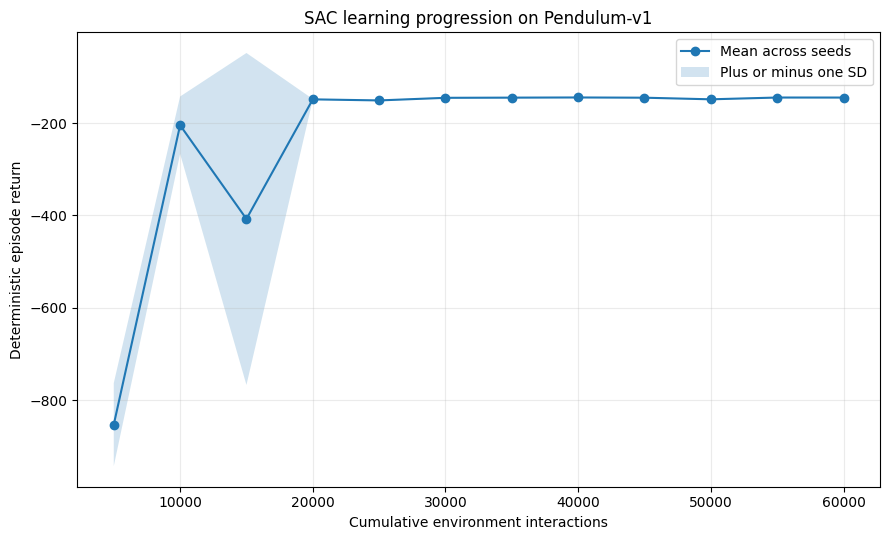

In [16]:
# Figure 1: mean learning progression across training seeds

periodic_summary = (
    completed_evaluations
    .groupby("environment_step", as_index=False)
    .agg(
        mean_return=("mean_return", "mean"),
        sd_across_seeds=("mean_return", "std"),
    )
    .sort_values("environment_step")
)

figure_path = FIGURE_DIR / "01_periodic_learning_curve.png"

plt.figure(figsize=(9, 5.5))
plt.plot(
    periodic_summary["environment_step"],
    periodic_summary["mean_return"],
    marker="o",
    label="Mean across seeds",
)
plt.fill_between(
    periodic_summary["environment_step"],
    periodic_summary["mean_return"] - periodic_summary["sd_across_seeds"],
    periodic_summary["mean_return"] + periodic_summary["sd_across_seeds"],
    alpha=0.2,
    label="Plus or minus one SD",
)
plt.xlabel("Cumulative environment interactions")
plt.ylabel("Deterministic episode return")
plt.title("SAC learning progression on Pendulum-v1")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(figure_path, dpi=220, bbox_inches="tight")
plt.show()


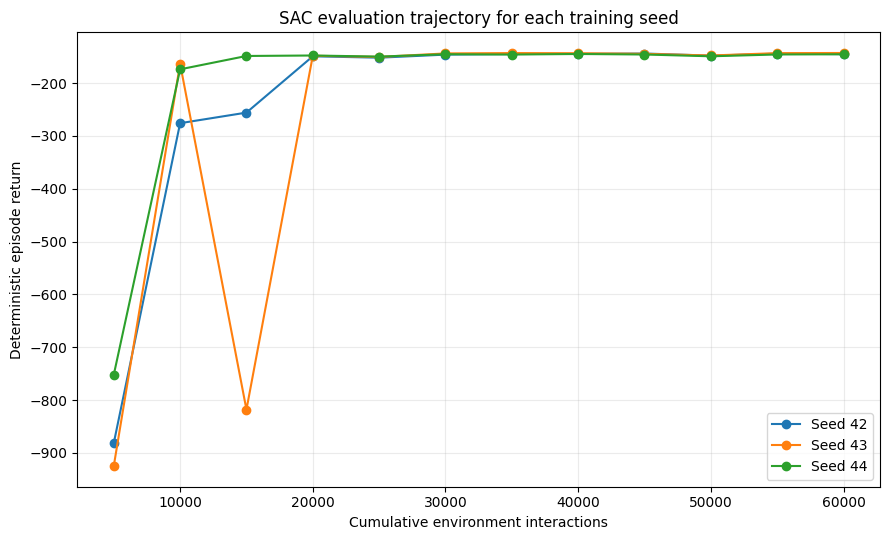

In [17]:
# Figure 2: seed-level trajectories

figure_path = FIGURE_DIR / "02_seed_trajectories.png"

plt.figure(figsize=(9, 5.5))

for seed in TRAINING_SEEDS:
    seed_frame = (
        completed_evaluations.loc[
            completed_evaluations["training_seed"] == seed
        ]
        .sort_values("environment_step")
    )

    plt.plot(
        seed_frame["environment_step"],
        seed_frame["mean_return"],
        marker="o",
        label=f"Seed {seed}",
    )

plt.xlabel("Cumulative environment interactions")
plt.ylabel("Deterministic episode return")
plt.title("SAC evaluation trajectory for each training seed")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(figure_path, dpi=220, bbox_inches="tight")
plt.show()


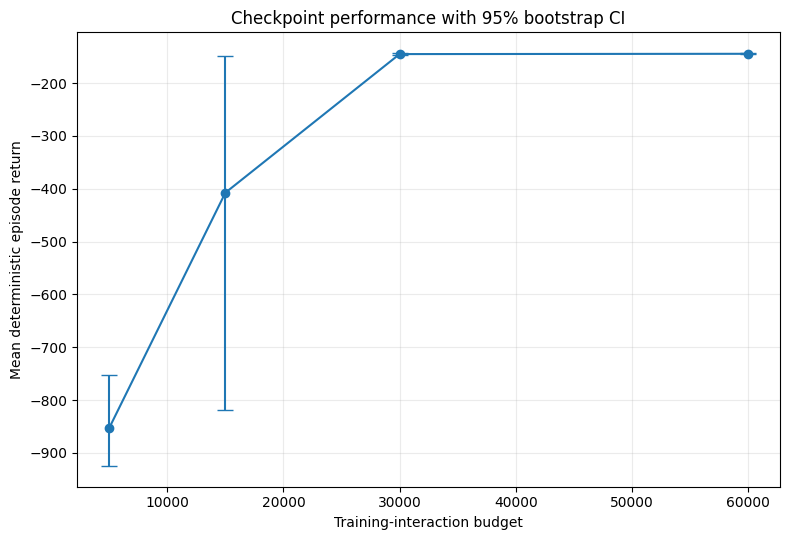

In [18]:
# Figure 3: checkpoint means and 95% bootstrap confidence intervals

figure_path = FIGURE_DIR / "03_checkpoint_mean_return_ci.png"

lower_error = (
    checkpoint_summary["mean_return"]
    - checkpoint_summary["ci_95_low"]
)

upper_error = (
    checkpoint_summary["ci_95_high"]
    - checkpoint_summary["mean_return"]
)

plt.figure(figsize=(8, 5.5))
plt.errorbar(
    checkpoint_summary["budget"],
    checkpoint_summary["mean_return"],
    yerr=np.vstack([lower_error, upper_error]),
    marker="o",
    capsize=6,
)
plt.xlabel("Training-interaction budget")
plt.ylabel("Mean deterministic episode return")
plt.title("Checkpoint performance with 95% bootstrap CI")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(figure_path, dpi=220, bbox_inches="tight")
plt.show()


## 9.2 Marginal improvement

In [19]:
marginal_rows = []

for start_budget, end_budget in zip(
    CHECKPOINT_BUDGETS[:-1],
    CHECKPOINT_BUDGETS[1:],
):
    start_frame = (
        reported_results.loc[
            reported_results["environment_step"] == start_budget,
            ["training_seed", "mean_return"],
        ]
        .rename(columns={"mean_return": "start_return"})
    )

    end_frame = (
        reported_results.loc[
            reported_results["environment_step"] == end_budget,
            ["training_seed", "mean_return"],
        ]
        .rename(columns={"mean_return": "end_return"})
    )

    paired = start_frame.merge(
        end_frame,
        on="training_seed",
        how="inner",
    ).sort_values("training_seed")

    paired["gain_per_1000"] = (
        paired["end_return"]
        - paired["start_return"]
    ) / (end_budget - start_budget) * 1000.0

    ci_low, ci_high = bootstrap_mean_confidence_interval(
        paired["gain_per_1000"].to_numpy(),
        resamples=CONFIG.bootstrap_resamples,
        seed=3030 + end_budget,
    )

    marginal_rows.append({
        "start_budget": int(start_budget),
        "end_budget": int(end_budget),
        "total_mean_gain": float(
            (paired["end_return"] - paired["start_return"]).mean()
        ),
        "mean_gain_per_1000": float(
            paired["gain_per_1000"].mean()
        ),
        "ci_95_low": ci_low,
        "ci_95_high": ci_high,
        "ci_includes_zero": bool(ci_low <= 0.0 <= ci_high),
    })

marginal_summary = pd.DataFrame(marginal_rows)
marginal_summary


,start_budget,end_budget,total_mean_gain,mean_gain_per_1000,ci_95_low,ci_95_high,ci_includes_zero
0,5000,15000,445.156667,44.515667,10.688000,62.535000,False
1,15000,30000,262.303333,17.486889,0.221333,44.925333,False
2,30000,60000,0.550000,0.018333,-0.003667,0.031333,True


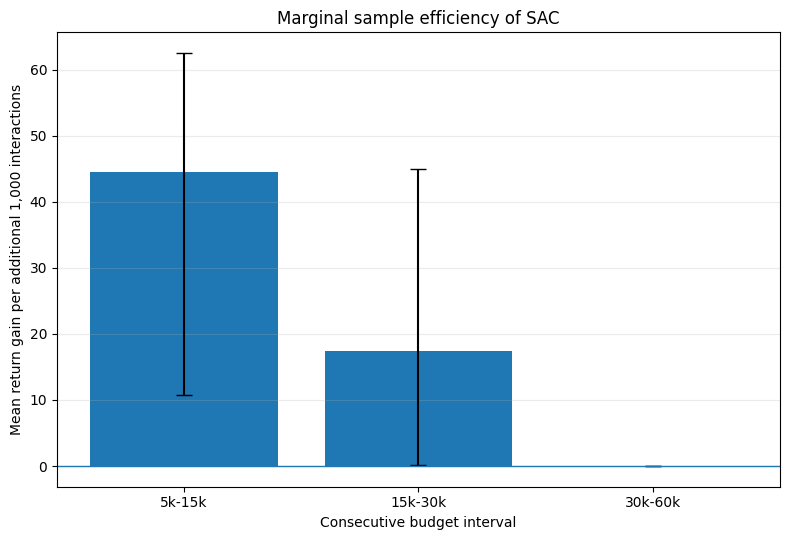

In [20]:
# Figure 4: marginal return gain per additional 1,000 interactions

labels = [
    f"{start // 1000}k-{end // 1000}k"
    for start, end in zip(
        marginal_summary["start_budget"],
        marginal_summary["end_budget"],
    )
]

lower_error = (
    marginal_summary["mean_gain_per_1000"]
    - marginal_summary["ci_95_low"]
)

upper_error = (
    marginal_summary["ci_95_high"]
    - marginal_summary["mean_gain_per_1000"]
)

figure_path = FIGURE_DIR / "04_marginal_improvement_per_1k.png"

plt.figure(figsize=(8, 5.5))
plt.bar(
    labels,
    marginal_summary["mean_gain_per_1000"],
    yerr=np.vstack([lower_error, upper_error]),
    capsize=6,
)
plt.axhline(0.0, linewidth=1.0)
plt.xlabel("Consecutive budget interval")
plt.ylabel("Mean return gain per additional 1,000 interactions")
plt.title("Marginal sample efficiency of SAC")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig(figure_path, dpi=220, bbox_inches="tight")
plt.show()


## 9.3 Runtime

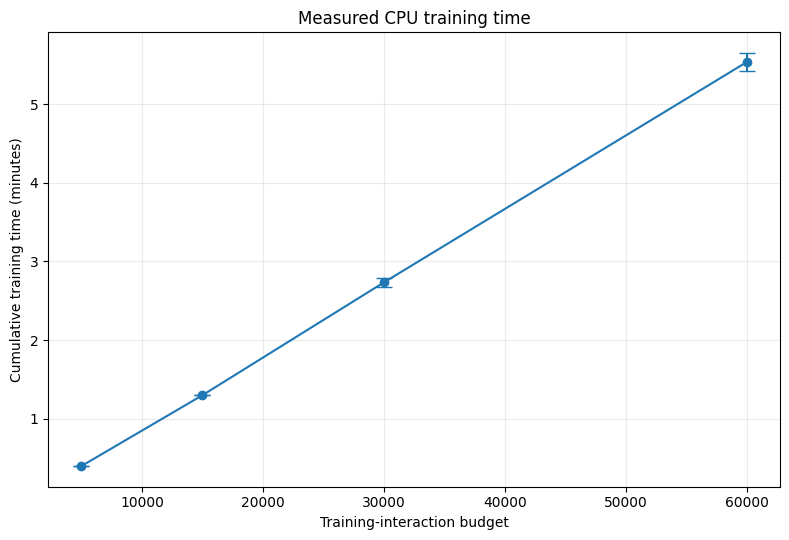

,budget,mean_minutes,sd_minutes
0,5000,0.400000,0.000000
1,15000,1.300000,0.000000
2,30000,2.733333,0.057735
3,60000,5.533333,0.115470


In [21]:
runtime_summary = (
    reported_results
    .groupby("environment_step", as_index=False)
    .agg(
        mean_minutes=("elapsed_minutes", "mean"),
        sd_minutes=("elapsed_minutes", "std"),
    )
    .rename(columns={"environment_step": "budget"})
)

figure_path = FIGURE_DIR / "05_training_time_by_budget.png"

plt.figure(figsize=(8, 5.5))
plt.errorbar(
    runtime_summary["budget"],
    runtime_summary["mean_minutes"],
    yerr=runtime_summary["sd_minutes"],
    marker="o",
    capsize=6,
)
plt.xlabel("Training-interaction budget")
plt.ylabel("Cumulative training time (minutes)")
plt.title("Measured CPU training time")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(figure_path, dpi=220, bbox_inches="tight")
plt.show()

runtime_summary


# 10. Result interpretation

The group mean improved from **-852.72** at 5,000 interactions to **-145.26** at 30,000 interactions. Increasing the budget from 30,000 to 60,000 interactions changed the mean to **-144.71**, an improvement of only **0.55 return points**.

The early intervals produced much larger gains:

- 5k to 15k: about **44.52 points per additional 1,000 interactions**
- 15k to 30k: about **17.49 points per additional 1,000 interactions**
- 30k to 60k: about **0.018 points per additional 1,000 interactions**

The paired bootstrap interval for the 30k-to-60k marginal gain includes zero. Under the predefined 20-return-point tolerance, **30,000 interactions is therefore the practical diminishing-returns point for this tested configuration**.

Seed 43 learned more slowly at 15,000 interactions, producing high seed-to-seed variability at that checkpoint. By 30,000 interactions, the three seed means were tightly grouped. The conclusion is limited to this environment, architecture, seed set and evaluation design; it does not establish that SAC is universally more sample-efficient than other algorithms.


# 11. References

[1] T. Haarnoja, A. Zhou, P. Abbeel, and S. Levine, “Soft Actor-Critic: Off-Policy Maximum Entropy Deep Reinforcement Learning with a Stochastic Actor,” *Proceedings of the 35th International Conference on Machine Learning*, PMLR, vol. 80, pp. 1861–1870, 2018. https://proceedings.mlr.press/v80/haarnoja18b.html

[2] T. Haarnoja et al., “Soft Actor-Critic Algorithms and Applications,” arXiv:1812.05905, 2018. https://arxiv.org/abs/1812.05905

[3] V. Mnih et al., “Human-level control through deep reinforcement learning,” *Nature*, vol. 518, pp. 529–533, 2015. https://doi.org/10.1038/nature14236

[4] P. Henderson, R. Islam, P. Bachman, J. Pineau, D. Precup, and D. Meger, “Deep Reinforcement Learning that Matters,” *Proceedings of the AAAI Conference on Artificial Intelligence*, vol. 32, no. 1, 2018. https://arxiv.org/abs/1709.06560

[5] M. Towers et al., “Gymnasium: A Standard Interface for Reinforcement Learning Environments,” arXiv:2407.17032, 2024. https://arxiv.org/abs/2407.17032

[6] Farama Foundation, “Pendulum — Gymnasium Documentation.” https://gymnasium.farama.org/environments/classic_control/pendulum/ (accessed 6 August 2026).

[7] M. Abadi et al., “TensorFlow: A System for Large-Scale Machine Learning,” *12th USENIX Symposium on Operating Systems Design and Implementation*, pp. 265–283, 2016. https://www.usenix.org/conference/osdi16/technical-sessions/presentation/abadi
